# Experiment 2: Configuration study on the test set 

The main method is frozen. This notebook asks a question: *does the conclusion depend on the preprocessing or on the classifier configuration?* Twelve configurations, declared below, are each run through the **whole pipeline**.

In [1]:
# Imports and config
!pip install -q opencv-python scikit-learn scipy tqdm joblib

import os, json, random, warnings, math, time, gc
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.sparse import csr_matrix, diags, identity
from scipy.sparse.linalg import spsolve
from scipy.spatial.distance import cdist
from scipy.ndimage import distance_transform_edt
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = "/content/drive/MyDrive/cbis_ddsm_grc_project_v3_dicom"      # the DICOM-based project folder
CONFIG = json.load(open(os.path.join(DRIVE_ROOT, "config.json")))
globals().update(CONFIG)
SEED = CONFIG["SEED"]
random.seed(SEED); np.random.seed(SEED)

LAP_WINDOW, LAP_EPSILON = 3, 1e-7
MU_GRID = [0.1, 1.0, 10.0]
N_BOOT = 2000                         # patient-level bootstrap resamples for the paired comparisons
N_BOOT_AUC = 200                      # for the validation band-AUC intervals
DEF_ROWS, BAND_ROWS = 300, 200        # rows per class per image: definite pixels / unknown-band pixels
MAX_FIT, MAX_TUNE_FIT = 20000, 8000
INTENSITY_SCALES = [5, 9, 15]
NB6_DIR = os.path.join(RESULTS_DIR, "nb6"); os.makedirs(NB6_DIR, exist_ok=True)
print("Config loaded.")


Mounted at /content/drive
Config loaded.


## Data and frozen settings

In [2]:
final_df_loaded = pd.read_csv(os.path.join(RESULTS_DIR, "final_df_loaded.csv"))
raw_arch = np.load(os.path.join(PREPROCESSED_DIR, "raw_crops.npz"))
gt_arch  = np.load(os.path.join(PREPROCESSED_DIR, "gt_masks.npz"))
roi_arch = np.load(os.path.join(PREPROCESSED_DIR, "rois.npz"))
class_of, patient_of = dict(zip(final_df_loaded['image_id'], final_df_loaded['class'])), dict(zip(final_df_loaded['image_id'], final_df_loaded['patient_id']))

sp = json.load(open(os.path.join(RESULTS_DIR, "train_test_split.json")))
train_ids, val_ids, test_ids = set(sp['train_ids']), set(sp['val_ids']), set(sp['test_ids'])
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    for unit in ('lesions', 'patients'):
        assert not (set(sp[f'{a}_{unit}']) & set(sp[f'{b}_{unit}'])), f"{unit} leakage {a}/{b}"

RAW = {i: raw_arch[i].astype(np.float32) for i in raw_arch.files}
GT  = {i: gt_arch[i] for i in gt_arch.files}
usable = set(RAW) & set(GT)
TRAIN_IDS, VAL_IDS = sorted(train_ids & usable), sorted(val_ids & usable)
EVAL_TEST = sorted(test_ids & usable)
assert len(EVAL_TEST) == len(test_ids), "some test images are unusable - a configuration study must use the whole test split"
FINAL_K = json.load(open(os.path.join(MODELS_DIR, "selected_K.json")))['selected_K']
NB4 = json.load(open(os.path.join(RESULTS_DIR, "final_results.json")))
L5_MAIN = NB4['config']['layer5_variant']; L5_PLAIN = L5_MAIN.replace('hybrid', 'plain')
preprocessed_results = {i: {'gt_mask': GT[i], 'class': class_of[i], 'patient_id': patient_of[i]} for i in usable}
print(f"train {len(TRAIN_IDS)} | val {len(VAL_IDS)} | test {len(EVAL_TEST)} images; K = {FINAL_K}; Layer 5 variant = {L5_MAIN}")
print("Every run below is scored on exactly these", len(EVAL_TEST), "test images.")


train 642 | val 156 | test 269 images; K = 8; Layer 5 variant = paper_hybrid_mu1
Every run below is scored on exactly these 269 test images.


## Feature functions (Layers 1-3), classifier wrapper

In [ ]:
CHANNELS = [(ps, kind) for ps in PATCH_SIZES for kind in ('lipw', 'lbpw')]; N_CH = len(CHANNELS); WIN = PATCH_SINGLE
ROW_CHUNK = 96

def apply_layer1(roi, patch_size, lambda_val=None):          
    lam = LAMBDA_VAL if lambda_val is None else lambda_val
    half = patch_size // 2
    padded = np.pad(roi, half, mode='reflect').astype(np.float32)
    patches = sliding_window_view(padded, (patch_size, patch_size))
    lipw = 1.0 / (1.0 + np.exp(-lam * (patches - 0.5))); lipw_map = lipw.mean(axis=(-2, -1)).astype(np.float32)
    centre = patches[:, :, half, half][:, :, None, None]
    centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
    xor = patches + centre - 2 * patches * centre
    lbpw = 1.0 / (1.0 + np.exp(-lam * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
    lbpw_map = (lbpw.sum(axis=(-2, -1)) / (patch_size * patch_size - 1)).astype(np.float32)
    return lipw_map, lbpw_map

def layer1_stack(roi):
    h, w = roi.shape; out = np.empty((h, w, N_CH), np.float32); c = 0
    for ps in PATCH_SIZES:
        half = ps // 2; padded = np.pad(roi, half, mode='reflect').astype(np.float32)
        for r0 in range(0, h, ROW_CHUNK):
            r1 = min(h, r0 + ROW_CHUNK)
            patches = sliding_window_view(padded[r0:r1 + 2 * half, :], (ps, ps))
            lipw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (patches - 0.5)))
            out[r0:r1, :, c] = lipw.mean(axis=(-2, -1))
            centre = patches[:, :, half, half][:, :, None, None]
            centre = np.where(np.abs(centre - 0.5) < 1e-6, centre + 1e-6, centre)
            xor = patches + centre - 2 * patches * centre
            lbpw = 1.0 / (1.0 + np.exp(-LAMBDA_VAL * (xor - 0.5))); lbpw[:, :, half, half] = 0.0
            out[r0:r1, :, c + 1] = lbpw.sum(axis=(-2, -1)) / (ps * ps - 1)
        c += 2
    return out

_t = np.random.default_rng(0).random((61, 73)).astype(np.float32)
_s = layer1_stack(_t)
for _i, ps in enumerate(PATCH_SIZES):
    _l, _b = apply_layer1(_t, ps)
    assert np.abs(_s[:, :, 2 * _i] - _l).max() < 1e-5 and np.abs(_s[:, :, 2 * _i + 1] - _b).max() < 1e-5, "chunked Layer 1 differs"
print("Chunked Layer 1 matches the Notebook-2 implementation.")

def center_patches(P):
    P = P.reshape(len(P), N_CH, -1); return (P - P.mean(axis=2, keepdims=True)).reshape(len(P), -1)

def layer2_scores(stack_z, templates):
    h, w, C = stack_z.shape; K = len(templates); half = WIN // 2
    Tc = center_patches(templates.reshape(K, -1).astype(np.float32)); Wm = np.sign(Tc); Wm[Wm == 0] = 1.0; Wn = np.linalg.norm(Wm, axis=1)
    padded = np.pad(stack_z, ((half, half), (half, half), (0, 0)), mode='reflect'); out = np.empty((h, w, K), np.float32)
    for r0 in range(0, h, ROW_CHUNK // 2):
        r1 = min(h, r0 + ROW_CHUNK // 2)
        win = sliding_window_view(padded[r0:r1 + 2 * half], (WIN, WIN), axis=(0, 1))
        P = center_patches(win.reshape((r1 - r0) * w, C * WIN * WIN).astype(np.float32))
        sc = ((P @ Wm.T) / (np.linalg.norm(P, axis=1, keepdims=True) * Wn[None, :] + 1e-8) + 1.0) * 0.5
        out[r0:r1] = sc.reshape(r1 - r0, w, K)
    return out

def _odd(w, h, ww):
    w = min(w, min(h, ww)); return w if w % 2 == 1 else w - 1
def box(a, w):
    h, ww = a.shape[:2]; w = _odd(w, h, ww)
    return cv2.boxFilter(a, -1, (w, w), borderType=cv2.BORDER_REFLECT)
def pool(maps_hwk, w):
    k = maps_hwk.shape[2]; out = np.empty_like(maps_hwk, dtype=np.float32)
    for c in range(k): out[:, :, c] = box(maps_hwk[:, :, c], w)
    t = out.sum(axis=2, keepdims=True)
    return np.where(t > 1e-8, out / t, 1.0 / k).astype(np.float32)

BLOCKS = ['hist7', 'hist31', 'int3', 'ctx']
def feature_maps(roi, sm):
    out = {'hist7': pool(sm, 7), 'hist31': pool(sm, 31), 'int3': np.stack([box(roi, s) for s in (5, 9, 15)], axis=2)}
    m = {s: box(roi, s) for s in (5, 9, 15, 31, 63)}; sq = {s: box(roi * roi, s) for s in (5, 9, 15)}
    std = [np.sqrt(np.maximum(sq[s] - m[s] ** 2, 0)) for s in (5, 9, 15)]
    g = cv2.GaussianBlur(roi, (0, 0), 2); gm = np.sqrt(cv2.Sobel(g, cv2.CV_32F, 1, 0) ** 2 + cv2.Sobel(g, cv2.CV_32F, 0, 1) ** 2)
    out['ctx'] = np.stack(std + [m[31], m[63], m[5] - m[31], box(gm, 9)], axis=2).astype(np.float32)
    return out

K3 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
def make_trimap_from_mask(mask):                              
    m = (mask > 127).astype(np.uint8)
    tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[cv2.erode(m, K3, iterations=TRIMAP_ERODE_ITERS) == 1] = 255
    if (tm == 255).sum() < 10: tm[m == 1] = 255
    return tm
def _erode_capped(mask, n):
    out = mask.copy()
    for _ in range(n):
        nxt = cv2.erode(out, K3)
        if nxt.sum() == 0: break
        out = nxt
    return out
def make_eval_trimap(gt_u8):                                  
    m = (gt_u8 > 127).astype(np.uint8); tm = np.full(m.shape, 128, np.uint8)
    tm[cv2.dilate(m, K3, iterations=TRIMAP_DILATE_ITERS) == 0] = 0
    tm[_erode_capped(m, TRIMAP_ERODE_ITERS) == 1] = 255
    return tm

def fast_decision(svm, Xs):
    sv, coef, b, g = svm.support_vectors_.astype(np.float32), svm.dual_coef_.astype(np.float32).ravel(), float(svm.intercept_[0]), float(svm._gamma)
    try:
        import torch
        dev = 'cuda' if torch.cuda.is_available() else 'cpu'
        svt, ct = torch.from_numpy(sv).to(dev), torch.from_numpy(coef).to(dev); sq = (svt ** 2).sum(1); out = []
        for i in range(0, len(Xs), 20000):
            xt = torch.from_numpy(np.ascontiguousarray(Xs[i:i + 20000], dtype=np.float32)).to(dev)
            d2 = (xt ** 2).sum(1, keepdim=True) + sq[None, :] - 2 * xt @ svt.T
            out.append((torch.exp(-g * d2.clamp_min(0)) @ ct + b).cpu().numpy())
        return np.concatenate(out)
    except Exception:
        out = []; sq = (sv ** 2).sum(1)
        for i in range(0, len(Xs), 5000):
            x = Xs[i:i + 5000].astype(np.float32); d2 = (x ** 2).sum(1)[:, None] + sq[None, :] - 2 * x @ sv.T
            out.append(np.exp(-g * np.maximum(d2, 0)) @ coef + b)
        return np.concatenate(out)
print("Feature functions ready.")

Chunked Layer 1 matches the Notebook-2 implementation.
Feature functions ready.


In [ ]:
try:
    import torch
    DEV = 'cuda' if torch.cuda.is_available() else 'numpy'
except ImportError:
    torch, DEV = None, 'numpy'

class FastRBFProba:
    def __init__(self, svm, scaler, chunk=4096):
        self.mu, self.sd = scaler.mean_.astype(np.float64), scaler.scale_.astype(np.float64)
        self.sv = svm.support_vectors_.astype(np.float64); self.coef = svm.dual_coef_[0].astype(np.float64)
        self.b, self.gamma = float(svm.intercept_[0]), float(svm._gamma)
        self.A, self.B, self.chunk = float(svm.probA_[0]), float(svm.probB_[0]), chunk
        self.sv_sq = (self.sv ** 2).sum(1)
        self.sv32, self.sq32, self.c32 = self.sv.astype(np.float32), self.sv_sq.astype(np.float32), self.coef.astype(np.float32)
        if DEV != 'numpy':
            self.t_sv, self.t_c, self.t_sq = [torch.tensor(a, dtype=torch.float32, device=DEV) for a in (self.sv, self.coef, self.sv_sq)]
    def decision(self, X):
        out = np.empty(len(X), np.float64)
        for s in range(0, len(X), self.chunk):
            Z = ((X[s:s + self.chunk].astype(np.float64) - self.mu) / self.sd).astype(np.float32)
            if DEV == 'numpy':
                d2 = (Z ** 2).sum(1)[:, None] + self.sq32[None, :] - 2.0 * Z @ self.sv32.T
                np.maximum(d2, 0, out=d2); d2 *= -np.float32(self.gamma); np.exp(d2, out=d2)
                out[s:s + self.chunk] = (d2 @ self.c32).astype(np.float64) + self.b
            else:
                Zt = torch.tensor(Z, device=DEV)
                d2 = (Zt ** 2).sum(1, keepdim=True) + self.t_sq[None, :] - 2.0 * Zt @ self.t_sv.T
                out[s:s + self.chunk] = (torch.exp(-self.gamma * d2.clamp_min(0)) @ self.t_c).double().cpu().numpy() + self.b
        return out
    def proba(self, X):
        return (1.0 / (1.0 + np.exp(self.A * self.decision(X) - self.B))).astype(np.float32)

## Layer 5 and metrics

In [ ]:
def _downscale_trimap(trimap, hs, ws):
    h0, w0 = trimap.shape
    tm_s = cv2.resize(trimap, (ws, hs), interpolation=cv2.INTER_NEAREST)
    fg0 = np.argwhere(trimap == 255)
    if len(fg0) and not (tm_s == 255).any():
        cy, cx = fg0.mean(axis=0)
        tm_s[min(hs - 1, int(cy * hs / h0)), min(ws - 1, int(cx * ws / w0))] = 255
    return tm_s

def build_matting_laplacian(feat, win=LAP_WINDOW, eps=LAP_EPSILON):
    h, w = feat.shape; n = h * w; k = win * win
    idx = np.arange(n).reshape(h, w)
    iw = sliding_window_view(idx, (win, win)).reshape(-1, k)
    fw = sliding_window_view(feat.astype(np.float64), (win, win)).reshape(-1, k)
    mu = fw.mean(axis=1, keepdims=True)
    var = fw.var(axis=1, keepdims=True) + eps / k
    d = fw - mu
    W = (1.0 + d[:, :, None] * d[:, None, :] / var[:, :, None]) / k
    vals = np.eye(k)[None] - W
    rows = np.repeat(iw[:, :, None], k, axis=2).ravel()
    cols = np.repeat(iw[:, None, :], k, axis=1).ravel()
    return csr_matrix((vals.ravel(), (rows, cols)), shape=(n, n))

def _laplacian_loop(feat, win=LAP_WINDOW, eps=LAP_EPSILON):      
    h, w = feat.shape; n = h * w; half = win // 2; idx = np.arange(n).reshape(h, w)
    rows, cols, vals = [], [], []
    for i in range(half, h - half):
        for j in range(half, w - half):
            wi = idx[i-half:i+half+1, j-half:j+half+1].ravel()
            wf = feat[i-half:i+half+1, j-half:j+half+1].ravel().astype(np.float64)
            k = len(wf); var = wf.var() + eps / k; df = (wf - wf.mean()).reshape(-1, 1)
            Wm = (1.0 + (df @ df.T) / var) / k
            for a in range(k):
                for b in range(k):
                    rows.append(wi[a]); cols.append(wi[b]); vals.append((1.0 if a == b else 0.0) - Wm[a, b])
    return csr_matrix((vals, (rows, cols)), shape=(n, n))

_t = np.random.default_rng(0).random((14, 17)).astype(np.float32)
assert abs(build_matting_laplacian(_t) - _laplacian_loop(_t)).max() < 1e-9
print("Vectorised Matting Laplacian matches the v1 loop implementation.")

GAMMA = HYBRID_GAMMA                    
def make_variants():
    v = {'legacy_hybrid': dict(lap='prob',  mu=0.0, w_int=0.0, post=GAMMA),
         'legacy_plain' : dict(lap='prob',  mu=0.0, w_int=0.0, post=None)}
    for m in MU_GRID:
        v[f'paper_hybrid_mu{m:g}'] = dict(lap='image', mu=m, w_int=1 - GAMMA, post=None)
        v[f'paper_plain_mu{m:g}']  = dict(lap='image', mu=m, w_int=0.0,       post=None)
    return v
VARIANTS = make_variants()

def _grid_size(shape, max_nodes=MAX_NODES):
    h0, w0 = shape
    s = min(1.0, math.sqrt(max_nodes / float(h0 * w0)))
    return max(8, int(round(h0 * s))), max(8, int(round(w0 * s)))

def solve_alpha(prob_map, trimap, roi, variant, max_nodes=MAX_NODES, lam=LAMBDA_PROPAGATION):
    h0, w0 = prob_map.shape
    hs, ws = _grid_size((h0, w0), max_nodes)
    prob_s = cv2.resize(prob_map, (ws, hs), interpolation=cv2.INTER_LINEAR)
    roi_s  = cv2.resize(roi,      (ws, hs), interpolation=cv2.INTER_LINEAR)
    tm_s   = _downscale_trimap(trimap, hs, ws)
    inten  = roi_s.astype(np.float32); rg = inten.max() - inten.min()
    inten  = (inten - inten.min()) / rg if rg > 1e-8 else np.zeros_like(inten)

    L = build_matting_laplacian(prob_s if variant['lap'] == 'prob' else roi_s)
    known  = ((tm_s == 255) | (tm_s == 0)).ravel().astype(np.float64)
    target = (tm_s == 255).ravel().astype(np.float64)
    A = L + lam * diags(known); b = lam * known * target
    if variant['mu'] > 0:                                             
        a0 = ((1 - variant['w_int']) * prob_s + variant['w_int'] * inten).ravel().astype(np.float64)
        A = A + variant['mu'] * identity(len(a0), format='csr'); b = b + variant['mu'] * a0
    try:
        alpha = spsolve(A.tocsc(), b)
    except Exception as e:
        print(f"  solve failed ({e}); using the probability map"); alpha = prob_s.ravel().astype(np.float64)
    alpha = np.clip(alpha.reshape(hs, ws), 0, 1).astype(np.float32)
    if variant['post'] is not None:                                   
        alpha = np.clip(variant['post'] * alpha + (1 - variant['post']) * inten, 0, 1)
    return cv2.resize(alpha, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

def trimap_only_alpha(trimap, mode='distance'):
    fg, bg = trimap == 255, trimap == 0
    alpha = np.zeros(trimap.shape, np.float32); alpha[fg] = 1.0
    unk = ~(fg | bg)
    if mode == 'one':
        alpha[unk] = 1.0
    elif mode == 'distance':
        d_fg, d_bg = distance_transform_edt(~fg), distance_transform_edt(~bg)
        alpha[unk] = (d_bg / np.maximum(d_fg + d_bg, 1e-6))[unk]
    elif mode != 'zero':
        raise ValueError(mode)
    return alpha

def trimap_only_on_grid(trimap, mode='distance', max_nodes=MAX_NODES):
    h0, w0 = trimap.shape; hs, ws = _grid_size((h0, w0), max_nodes)
    a = trimap_only_alpha(_downscale_trimap(trimap, hs, ws), mode)
    return cv2.resize(a, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(np.float32)

print(f"{len(VARIANTS)} Layer 5 variants: {list(VARIANTS)}")
VARIANTS['cf_matting'] = dict(lap='image', mu=0.0, w_int=0.0, post=None)   

Vectorised Matting Laplacian matches the v1 loop implementation.
8 Layer 5 variants: ['legacy_hybrid', 'legacy_plain', 'paper_hybrid_mu0.1', 'paper_plain_mu0.1', 'paper_hybrid_mu1', 'paper_plain_mu1', 'paper_hybrid_mu10', 'paper_plain_mu10']


In [ ]:
def dice(pred, gt):
    s = pred.sum() + gt.sum()
    return float(2 * np.logical_and(pred, gt).sum() / s) if s > 0 else np.nan
def sensitivity(pred, gt):
    tp, fn = np.logical_and(pred, gt).sum(), np.logical_and(~pred, gt).sum()
    return float(tp / (tp + fn)) if (tp + fn) > 0 else np.nan
def specificity(pred, gt):
    tn, fp = np.logical_and(~pred, ~gt).sum(), np.logical_and(pred, ~gt).sum()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else np.nan
def hd95(pred, gt):
    if pred.sum() == 0 or gt.sum() == 0: return np.nan
    pe, ge = pred ^ ndimage.binary_erosion(pred), gt ^ ndimage.binary_erosion(gt)
    pp, gp = np.argwhere(pe), np.argwhere(ge)
    if len(pp) == 0 or len(gp) == 0: return np.nan
    return float(np.percentile(np.concatenate([cdist(pp, gp).min(axis=1), cdist(gp, pp).min(axis=1)]), HD95_PERCENTILE))
def alpha_mae(alpha, gt):
    return float(np.abs(alpha - gt.astype(np.float32)).mean())

def evaluate_alpha_realmask(iid, alpha, thr=ALPHA_THRESHOLD):
    d = preprocessed_results[iid]
    gt = d['gt_mask']
    if gt.shape[:2] != alpha.shape:
        gt = cv2.resize(gt, (alpha.shape[1], alpha.shape[0]), interpolation=cv2.INTER_NEAREST)
    gt = gt > 127; pred = alpha >= thr
    return {'image_id': iid, 'class': d['class'], 'patient_id': d['patient_id'], 'dice': dice(pred, gt),
            'sensitivity': sensitivity(pred, gt), 'specificity': specificity(pred, gt),
            'hd95': hd95(pred, gt), 'alpha_mae': alpha_mae(alpha, gt)}

def eval_many(alphas):
    return pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas.items()])

def summarise_per_class(df):
    out = []
    for cls in TARGET_CLASSES:
        s = df[df['class'] == cls]
        if len(s):
            out.append({'class': cls, 'n': len(s), 'dice': s['dice'].mean(), 'dice_std': s['dice'].std(),
                        'sensitivity': s['sensitivity'].mean(), 'specificity': s['specificity'].mean(),
                        'hd95': s['hd95'].mean(), 'alpha_mae': s['alpha_mae'].mean()})
    return pd.DataFrame(out)

def paired_bootstrap(df_a, df_b, col='dice', n_boot=N_BOOT, seed=SEED):
    m = df_a[['image_id', 'patient_id', col]].merge(df_b[['image_id', col]], on='image_id', suffixes=('_a', '_b'))
    m['d'] = m[f'{col}_a'] - m[f'{col}_b']; m = m.dropna(subset=['d'])
    g = m.groupby('patient_id')['d'].agg(['sum', 'count'])
    s, c = g['sum'].to_numpy(), g['count'].to_numpy()
    rng = np.random.default_rng(seed)
    ix = rng.integers(0, len(g), size=(n_boot, len(g)))
    boots = s[ix].sum(axis=1) / c[ix].sum(axis=1)
    return float(m['d'].mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5)), len(m)

print("Metrics ready.")

Metrics ready.


## The 12 declared configurations, seed-only baseline

In [ ]:
def to_u16(a):
    a = a.astype(np.float32); lo, hi = float(a.min()), float(a.max())
    return np.zeros(a.shape, np.uint16) if hi <= lo else ((a - lo) / (hi - lo) * 65535.0).astype(np.uint16)
def multiscale_clahe_u16(img16):
    f = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_FINE)).apply(img16)
    c = cv2.createCLAHE(clipLimit=CLAHE_CLIP_LIMIT, tileGridSize=tuple(CLAHE_TILE_COARSE)).apply(img16)
    return (f.astype(np.float32) + c.astype(np.float32)) / 2.0
def normalize01(a):
    a = a.astype(np.float32); lo, hi = a.min(), a.max()
    return (a - lo) / (hi - lo) if hi > lo else np.zeros_like(a)
def pwin(a, lo=1, hi=99):
    a = a.astype(np.float32); l, h = np.percentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1) if h > l else np.zeros_like(a)
def _lcn(a, w=31):
    a = a.astype(np.float32); m = cv2.boxFilter(a, -1, (w, w), borderType=cv2.BORDER_REFLECT)
    s = np.sqrt(np.maximum(cv2.boxFilter(a * a, -1, (w, w), borderType=cv2.BORDER_REFLECT) - m * m, 1e-6)); return (a - m) / (s + 1e-3 * a.std())

PREP_CONFIGS = {
    'P0 CLAHE (main method)'          : (lambda c: normalize01(multiscale_clahe_u16(to_u16(c))), LAMBDA_VAL),
    'P1 linear min-max'               : (lambda c: normalize01(c), LAMBDA_VAL),
    'P2 1-99 pct window'              : (lambda c: pwin(c), LAMBDA_VAL),
    'P3 log + pct window'             : (lambda c: pwin(np.log1p(c)), LAMBDA_VAL),
    'P4 Gaussian(1) + pct window'     : (lambda c: pwin(cv2.GaussianBlur(c, (0, 0), 1.0)), LAMBDA_VAL),
    'P5 local contrast norm. (31)'    : (lambda c: pwin(_lcn(c)), LAMBDA_VAL),
    'P2, sigmoid scale 1.5'           : (lambda c: pwin(c), 1.5),
    'P2, sigmoid scale 15'            : (lambda c: pwin(c), 15.0),
}
MAIN_PREP = 'P0 CLAHE (main method)'
CLASSIFIERS = {
    'S0 hist7 + int3 (main)'          : (['hist7', 'int3'], 'def'),
    'S5 window 31'                    : (['hist31', 'int3'], 'def'),
    'S7 intensity only'               : (['int3'], 'def'),
    'S10 everything'                  : (['hist7', 'hist31', 'int3', 'ctx'], 'def'),
    'S10 everything, def + band rows' : (['hist7', 'hist31', 'int3', 'ctx'], 'both'),
}
MAIN_CLF = 'S0 hist7 + int3 (main)'
RUNS = [(n, 'preprocessing', n, MAIN_CLF) for n in PREP_CONFIGS] + \
       [(f"{MAIN_PREP.split()[0]} + {c}", 'classifier', MAIN_PREP, c) for c in CLASSIFIERS if c != MAIN_CLF]
RUN_NAMES = [r[0] for r in RUNS]
assert len(RUNS) == 12
print(f"{len(RUNS)} runs declared:")
for r in RUNS: print("  ", f"[{r[1]}]", r[0])

chk = [float(np.abs(PREP_CONFIGS[MAIN_PREP][0](RAW[i]) - roi_arch[i]).max()) for i in sorted(usable)[::10]]
print(f"P0 ROI vs stored rois.npz: max abs difference {max(chk):.2e} on {len(chk)} sampled images")
assert max(chk) < 1e-3, "P0 does not reproduce the stored ROIs"

for i in usable: preprocessed_results[i]['trimap_eval'] = make_eval_trimap(GT[i])
base_alphas = {'trimap_distance (same grid)': {i: trimap_only_on_grid(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST},
               'trimap_distance (full res)' : {i: trimap_only_alpha(preprocessed_results[i]['trimap_eval'], 'distance') for i in EVAL_TEST}}
base_df = {k: pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in v.items()]) for k, v in base_alphas.items()}
BASE = base_df['trimap_distance (same grid)']
print(f"Seed-only baseline (same grid) on the test split: Dice {BASE['dice'].mean():.4f}  (full res {base_df['trimap_distance (full res)']['dice'].mean():.4f})")

12 runs declared:
   [preprocessing] P0 CLAHE (main method)
   [preprocessing] P1 linear min-max
   [preprocessing] P2 1-99 pct window
   [preprocessing] P3 log + pct window
   [preprocessing] P4 Gaussian(1) + pct window
   [preprocessing] P5 local contrast norm. (31)
   [preprocessing] P2, sigmoid scale 1.5
   [preprocessing] P2, sigmoid scale 15
   [classifier] P0 + S5 window 31
   [classifier] P0 + S7 intensity only
   [classifier] P0 + S10 everything
   [classifier] P0 + S10 everything, def + band rows
P0 ROI vs stored rois.npz: max abs difference 0.00e+00 on 107 sampled images
Seed-only baseline (same grid) on the test split: Dice 0.8009  (full res 0.8063)


## Full pipeline per configuration (fit on train, tune on validation)

In [ ]:
FIT_TOUCHED = set()
BLOCKS_ALL = BLOCKS

def build_prep(cfg):
    global LAMBDA_VAL
    fn, lam = PREP_CONFIGS[cfg]; old = LAMBDA_VAL; LAMBDA_VAL = lam
    try:
        ROI = {i: fn(RAW[i]).astype(np.float32) for i in TRAIN_IDS + VAL_IDS}
        STK = {i: layer1_stack(ROI[i]).astype(np.float16) for i in TRAIN_IDS + VAL_IDS}
    finally:
        LAMBDA_VAL = old
    n, s, s2 = 0, np.zeros(N_CH), np.zeros(N_CH)
    for iid in TRAIN_IDS:
        st = STK[iid].astype(np.float64).reshape(-1, N_CH); s += st.sum(0); s2 += (st ** 2).sum(0); n += len(st)
    mean = (s / n).astype(np.float32); std = np.sqrt(np.maximum(s2 / n - (s / n) ** 2, 1e-12)).astype(np.float32)
    zf = lambda st: (st.astype(np.float32) - mean[None, None, :]) / std[None, None, :]
    rng, patches, half = np.random.default_rng(SEED), [], WIN // 2
    for iid in TRAIN_IDS:
        FIT_TOUCHED.add(iid); tm = make_trimap_from_mask(GT[iid])
        win = sliding_window_view(np.pad(zf(STK[iid]), ((half, half), (half, half), (0, 0)), mode='reflect'), (WIN, WIN), axis=(0, 1))
        for val in (255, 0):
            pos = np.argwhere(tm == val)
            if len(pos) == 0: continue
            if len(pos) > 200: pos = pos[rng.choice(len(pos), 200, replace=False)]
            patches.append(win[pos[:, 0], pos[:, 1]].reshape(len(pos), -1))
    km = KMeans(n_clusters=FINAL_K, init='k-means++', n_init=5, random_state=SEED).fit(center_patches(np.concatenate(patches).astype(np.float32)))
    templates = km.cluster_centers_.reshape(FINAL_K, N_CH, WIN, WIN).astype(np.float32)

    def rows(ids):
        r = np.random.default_rng(SEED); blocks = {b: [] for b in BLOCKS_ALL}; y, kind, grp = [], [], []
        for iid in sorted(ids):
            FIT_TOUCHED.add(iid); gt = GT[iid]; st_, ev_ = make_trimap_from_mask(gt), preprocessed_results[iid]['trimap_eval']; parts = []
            for kname, cap, ip, op in ((0, DEF_ROWS, np.argwhere(st_ == 255), np.argwhere(st_ == 0)),
                                       (1, BAND_ROWS, np.argwhere((ev_ == 128) & (gt > 127)), np.argwhere((ev_ == 128) & (gt <= 127)))):
                if len(ip) == 0 or len(op) == 0: continue
                k = min(len(ip), len(op), cap)
                for pos, lab in ((ip, 1), (op, 0)):
                    if len(pos) > k: pos = pos[r.choice(len(pos), k, replace=False)]
                    parts.append((pos, lab, kname))
            if not parts: continue
            fm = feature_maps(ROI[iid], layer2_scores(zf(STK[iid]), templates))
            for pos, lab, kname in parts:
                for b in BLOCKS_ALL: blocks[b].append(fm[b][pos[:, 0], pos[:, 1]])
                y.append(np.full(len(pos), lab)); kind.append(np.full(len(pos), kname)); grp += [iid] * len(pos)
        return {'X': {b: np.concatenate(v).astype(np.float32) for b, v in blocks.items()}, 'y': np.concatenate(y), 'kind': np.concatenate(kind), 'grp': np.array(grp)}
    TR = rows(TRAIN_IDS); VA = rows(VAL_IDS)
    return {'cfg': cfg, 'lam': lam, 'mean': mean, 'std': std, 'templates': templates, 'TR': TR, 'VA': VA}

VAL_PATS = sorted({patient_of[i] for i in VAL_IDS}); PIDX = {p: k for k, p in enumerate(VAL_PATS)}
_brng = np.random.default_rng(SEED + 1); BS_AUC = [_brng.integers(0, len(VAL_PATS), len(VAL_PATS)) for _ in range(N_BOOT_AUC)]
def band_auc_ci(y, dec, grp):
    pid = np.array([PIDX[patient_of[g]] for g in grp]); order = np.argsort(pid, kind='stable')
    sp_ = np.searchsorted(pid[order], np.arange(len(VAL_PATS) + 1)); by = [order[sp_[k]:sp_[k + 1]] for k in range(len(VAL_PATS))]
    out = []
    for b in BS_AUC:
        idx = np.concatenate([by[k] for k in b]); yy = y[idx]
        if 0 < yy.sum() < len(yy): out.append(roc_auc_score(yy, dec[idx]))
    return float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

def fit_classifier(B, blocks, train_kinds):
    TR, VA = B['TR'], B['VA']
    cat = lambda D: np.concatenate([D['X'][b] for b in blocks], axis=1)
    Xtr_all, Xva_all = cat(TR), cat(VA)
    kinds = {'def': (0,), 'both': (0, 1)}[train_kinds]
    mt, mv = np.isin(TR['kind'], kinds), np.isin(VA['kind'], kinds)
    sc = StandardScaler().fit(Xtr_all[mt]); Xtr, ytr = sc.transform(Xtr_all[mt]), TR['y'][mt]; Xva, yva = sc.transform(Xva_all[mv]), VA['y'][mv]
    rng = np.random.default_rng(SEED); gi = rng.choice(len(Xtr), min(MAX_TUNE_FIT, len(Xtr)), replace=False); best = (-1, None, None)
    for C in SVM_C_VALUES:
        for g in SVM_GAMMA_VALUES:
            m = SVC(kernel='rbf', C=C, gamma=g, class_weight='balanced', random_state=SEED).fit(Xtr[gi], ytr[gi])
            s = balanced_accuracy_score(yva, m.predict(Xva))
            if s > best[0] + 1e-12: best = (s, C, g)
    fi = rng.choice(len(Xtr), min(MAX_FIT, len(Xtr)), replace=False)
    svm = SVC(kernel='rbf', C=best[1], gamma=best[2], class_weight='balanced', probability=True, random_state=SEED).fit(Xtr[fi], ytr[fi])
    fast = FastRBFProba(svm, sc)
    xs = Xva_all[::max(1, len(Xva_all) // 2000)][:2000]; err = float(np.abs(fast.proba(xs) - svm.predict_proba(sc.transform(xs))[:, 1]).max())
    dec = fast.decision(Xva_all); k0, k1 = VA['kind'] == 0, VA['kind'] == 1
    lo, hi = band_auc_ci(VA['y'][k1], dec[k1], VA['grp'][k1])
    diag = {'val_bal_acc': float(best[0]), 'C': best[1], 'gamma': str(best[2]), 'fast_err': err, 'use_fast': err <= 0.01,
            'val_seed_auc': float(roc_auc_score(VA['y'][k0], dec[k0])), 'val_band_auc': float(roc_auc_score(VA['y'][k1], dec[k1])),
            'val_band_auc_lo': lo, 'val_band_auc_hi': hi, 'train_rows': int(mt.sum())}
    return {'svm': svm, 'sc': sc, 'fast': fast, 'blocks': blocks, 'diag': diag}

def prob_map(model, roi, stz, templates):
    fm = feature_maps(roi, layer2_scores(stz, templates)); h, w = roi.shape
    X = np.concatenate([fm[b].reshape(h * w, -1) for b in model['blocks']], axis=1)
    if model['diag']['use_fast']: p = model['fast'].proba(X)
    else: p = np.concatenate([model['svm'].predict_proba(model['sc'].transform(X[s:s + 20000]))[:, 1] for s in range(0, len(X), 20000)])
    return p.reshape(h, w).astype(np.float32)

def run_group(cfg, run_list):
    t0 = time.time(); B = build_prep(cfg); fn, lam = PREP_CONFIGS[cfg]
    models = {clf: fit_classifier(B, *CLASSIFIERS[clf]) for clf in sorted({r[3] for r in run_list})}
    tfit = (time.time() - t0) / 60
    alphas = {r[0]: {} for r in run_list}; global LAMBDA_VAL; old = LAMBDA_VAL
    for iid in tqdm(EVAL_TEST, desc=f"test: {cfg[:28]}", leave=False):
        roi = fn(RAW[iid]).astype(np.float32); LAMBDA_VAL = lam
        try: st = layer1_stack(roi)
        finally: LAMBDA_VAL = old
        stz = (st - B['mean'][None, None, :]) / B['std'][None, None, :]
        pm = {clf: prob_map(m, roi, stz, B['templates']) for clf, m in models.items()}
        for name, _, _, clf in run_list:
            alphas[name][iid] = solve_alpha(pm[clf], preprocessed_results[iid]['trimap_eval'], roi, VARIANTS[L5_MAIN])
    out = {}
    for name, fam, _, clf in run_list:
        df = pd.DataFrame([evaluate_alpha_realmask(i, a) for i, a in alphas[name].items()]); df.insert(0, 'run', name)
        meta = dict(models[clf]['diag']); meta.update(run=name, family=fam, prep=cfg, classifier=clf, lam=lam, minutes_fit=tfit, K=int(FINAL_K), layer5=L5_MAIN,
                                                     fit_touched=sorted(FIT_TOUCHED), test_ids=sorted(df['image_id']))
        df.to_csv(os.path.join(NB6_DIR, f"per_image_{name.replace(' ', '_').replace('/', '-')}.csv"), index=False)
        json.dump(meta, open(os.path.join(NB6_DIR, f"meta_{name.replace(' ', '_').replace('/', '-')}.json"), 'w'), default=float)
        out[name] = (df, meta)
    del B, models, alphas; gc.collect()
    return out
print("Pipeline ready.")

Pipeline ready.


## Run (finished groups are reloaded from Drive)

In [ ]:
def _f(name): return name.replace(' ', '_').replace('/', '-')
RESULTS_RUN, t_all = {}, time.time()
groups = {}
for r in RUNS: groups.setdefault(r[2], []).append(r)
for gi, (cfg, rl) in enumerate(groups.items(), 1):
    cached = all(os.path.exists(os.path.join(NB6_DIR, f"per_image_{_f(r[0])}.csv")) and os.path.exists(os.path.join(NB6_DIR, f"meta_{_f(r[0])}.json")) for r in rl)
    if cached:
        for r in rl: RESULTS_RUN[r[0]] = (pd.read_csv(os.path.join(NB6_DIR, f"per_image_{_f(r[0])}.csv")), json.load(open(os.path.join(NB6_DIR, f"meta_{_f(r[0])}.json"))))
        print(f"[{gi}/{len(groups)}] {cfg}: loaded {len(rl)} cached run(s)"); continue
    res = run_group(cfg, rl); RESULTS_RUN.update(res)
    for name, (df, meta) in res.items():
        print(f"[{gi}/{len(groups)}] {name:<44s} test Dice {df['dice'].mean():.4f} | val band AUC {meta['val_band_auc']:.3f} "
              f"[{meta['val_band_auc_lo']:.3f}, {meta['val_band_auc_hi']:.3f}] seed AUC {meta['val_seed_auc']:.3f} | C={meta['C']} gamma={meta['gamma']} | total {(time.time() - t_all) / 60:.1f} min")
RESULTS_RUN = {r[0]: RESULTS_RUN[r[0]] for r in RUNS}

[1/8] P0 CLAHE (main method)                       test Dice 0.7451 | val band AUC 0.502 [0.488, 0.516] seed AUC 0.562 | C=0.1 gamma=scale | total 30.7 min
[1/8] P0 + S5 window 31                            test Dice 0.7305 | val band AUC 0.508 [0.498, 0.520] seed AUC 0.623 | C=1 gamma=scale | total 30.7 min
[1/8] P0 + S7 intensity only                       test Dice 0.7496 | val band AUC 0.504 [0.491, 0.520] seed AUC 0.563 | C=1 gamma=scale | total 30.7 min
[1/8] P0 + S10 everything                          test Dice 0.7089 | val band AUC 0.511 [0.499, 0.525] seed AUC 0.648 | C=1 gamma=scale | total 30.7 min
[1/8] P0 + S10 everything, def + band rows         test Dice 0.7436 | val band AUC 0.506 [0.494, 0.520] seed AUC 0.630 | C=0.1 gamma=scale | total 30.7 min


[2/8] P1 linear min-max                            test Dice 0.7203 | val band AUC 0.503 [0.491, 0.514] seed AUC 0.580 | C=10 gamma=scale | total 37.2 min


[3/8] P2 1-99 pct window                           test Dice 0.7141 | val band AUC 0.515 [0.504, 0.527] seed AUC 0.618 | C=10 gamma=auto | total 43.9 min


[4/8] P3 log + pct window                          test Dice 0.7103 | val band AUC 0.515 [0.502, 0.526] seed AUC 0.622 | C=10 gamma=auto | total 50.2 min


[5/8] P4 Gaussian(1) + pct window                  test Dice 0.7013 | val band AUC 0.512 [0.501, 0.525] seed AUC 0.617 | C=1 gamma=scale | total 56.5 min


[6/8] P5 local contrast norm. (31)                 test Dice 0.7465 | val band AUC 0.499 [0.478, 0.518] seed AUC 0.530 | C=0.1 gamma=scale | total 62.8 min


[7/8] P2, sigmoid scale 1.5                        test Dice 0.7128 | val band AUC 0.513 [0.501, 0.525] seed AUC 0.620 | C=10 gamma=scale | total 69.1 min


[8/8] P2, sigmoid scale 15                         test Dice 0.7140 | val band AUC 0.512 [0.501, 0.525] seed AUC 0.617 | C=10 gamma=scale | total 75.3 min


## Tables and paired comparisons

In [ ]:
MAIN_RUN = RUN_NAMES[0]
mdf = RESULTS_RUN[MAIN_RUN][0]
rows, cmp_rows = [], []
for name, fam, _, _ in RUNS:
    df, meta = RESULTS_RUN[name]
    row = {'run': name, 'family': fam, 'n_test': len(df), 'val_bal_acc': meta['val_bal_acc'], 'val_seed_auc': meta['val_seed_auc'],
           'val_band_auc': meta['val_band_auc'], 'band_lo': meta['val_band_auc_lo'], 'band_hi': meta['val_band_auc_hi'],
           'dice': df['dice'].mean()}
    for c in TARGET_CLASSES: row[f'dice_{c}'] = df[df['class'] == c]['dice'].mean()
    row.update(sensitivity=df['sensitivity'].mean(), specificity=df['specificity'].mean(), hd95=df['hd95'].mean(), alpha_mae=df['alpha_mae'].mean(), baseline_dice=BASE['dice'].mean())
    m, lo, hi, n = paired_bootstrap(df, BASE, 'dice'); row.update(d_vs_baseline=m, d_vs_baseline_lo=lo, d_vs_baseline_hi=hi)
    cmp_rows.append({'run': name, 'vs': 'seed-only baseline (same grid)', 'metric': 'dice', 'mean_diff': m, 'ci_low': lo, 'ci_high': hi, 'n': n})
    if name != MAIN_RUN:
        m2, lo2, hi2, n2 = paired_bootstrap(df, mdf, 'dice'); row.update(d_vs_main=m2, d_vs_main_lo=lo2, d_vs_main_hi=hi2)
        cmp_rows.append({'run': name, 'vs': MAIN_RUN, 'metric': 'dice', 'mean_diff': m2, 'ci_low': lo2, 'ci_high': hi2, 'n': n2})
    else: row.update(d_vs_main=np.nan, d_vs_main_lo=np.nan, d_vs_main_hi=np.nan)
    rows.append(row)
tab = pd.DataFrame(rows); cmp_ci = pd.DataFrame(cmp_rows)
cmp_ci.to_csv(os.path.join(RESULTS_DIR, "config_study_paired_ci.csv"), index=False)

ci = lambda m, lo, hi: "" if pd.isna(m) else f"{m:+.4f} [{lo:+.4f}, {hi:+.4f}]"
T4 = pd.DataFrame({'Run': tab['run'], 'Val band AUC': [f"{a:.3f}" for a in tab['val_band_auc']], 'Test Dice': tab['dice'].map("{:.4f}".format)})
for c in TARGET_CLASSES: T4[f'Dice {c}'] = tab[f'dice_{c}'].map("{:.4f}".format)
T4['Seed-only baseline'] = tab['baseline_dice'].map("{:.4f}".format)
T4['Delta vs baseline [95% CI]'] = [ci(a, b, c) for a, b, c in zip(tab['d_vs_baseline'], tab['d_vs_baseline_lo'], tab['d_vs_baseline_hi'])]
T4['Delta vs main [95% CI]'] = [ci(a, b, c) for a, b, c in zip(tab['d_vs_main'], tab['d_vs_main_lo'], tab['d_vs_main_hi'])]
T4.insert(1, 'Family', tab['family'])
T4.to_csv(os.path.join(RESULTS_DIR, "table4_config_study.csv"), index=False)
S1 = tab[['run', 'family', 'n_test', 'dice', 'sensitivity', 'specificity', 'hd95', 'alpha_mae', 'val_bal_acc', 'val_seed_auc', 'val_band_auc', 'band_lo', 'band_hi']]
S1.to_csv(os.path.join(RESULTS_DIR, "tableS1_config_study_full.csv"), index=False)

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)
print("TABLE 4  Configuration study, test split (", len(EVAL_TEST), "images for every run). Validation columns are for context only.")
print(T4.to_string(index=False))
print("")
print("TABLE S1  Remaining metrics (test split)")
print(S1.round(4).to_string(index=False))
print("")
print("Seed-only baseline (same grid), per class:", {c: round(float(BASE[BASE['class'] == c]['dice'].mean()), 4) for c in TARGET_CLASSES})

p4 = os.path.join(RESULTS_DIR, "evaluation_per_image.csv")
if os.path.exists(p4):
    n4 = pd.read_csv(p4); m, lo, hi, n = paired_bootstrap(mdf, n4, 'dice')
    print("")
    print(f"Check vs Notebook 4 full_method: Dice {n4['dice'].mean():.4f} (Notebook 4) vs {mdf['dice'].mean():.4f} (this notebook, P0 rerun); paired difference {m:+.4f} [{lo:+.4f}, {hi:+.4f}], n={n}")
    print("Notebook 4 is the reference for Table 2; the P0 row here refits the same pipeline with this notebook's code path.")

TABLE 4  Configuration study, test split ( 269 images for every run). Validation columns are for context only.
                                 Run        Family Val band AUC Test Dice Dice CIRC Dice SPIC Dice MISC Seed-only baseline Delta vs baseline [95% CI]     Delta vs main [95% CI]
              P0 CLAHE (main method) preprocessing        0.502    0.7451    0.7264    0.7963    0.7142             0.8009 -0.0558 [-0.0709, -0.0415]                           
                   P1 linear min-max preprocessing        0.503    0.7203    0.6937    0.7711    0.6976             0.8009 -0.0805 [-0.0986, -0.0631] -0.0248 [-0.0371, -0.0135]
                  P2 1-99 pct window preprocessing        0.515    0.7141    0.6791    0.7599    0.7041             0.8009 -0.0868 [-0.1048, -0.0699] -0.0310 [-0.0428, -0.0191]
                 P3 log + pct window preprocessing        0.515    0.7103    0.6803    0.7588    0.6930             0.8009 -0.0905 [-0.1091, -0.0735] -0.0348 [-0.0455, -0.0239]
    

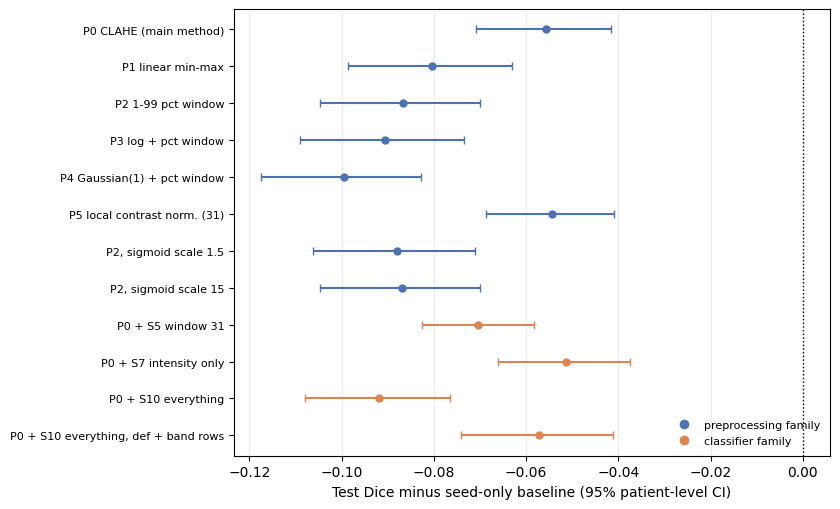

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
col = {'preprocessing': '#4C72B0', 'classifier': '#DD8452'}
ys = np.arange(len(tab))[::-1]
for y, (_, r) in zip(ys, tab.iterrows()):
    ax.errorbar(r['d_vs_baseline'], y, xerr=[[r['d_vs_baseline'] - r['d_vs_baseline_lo']], [r['d_vs_baseline_hi'] - r['d_vs_baseline']]],
                fmt='o', color=col[r['family']], ecolor=col[r['family']], capsize=3, ms=5)
ax.axvline(0, color='k', lw=1, ls=':'); ax.set_yticks(ys); ax.set_yticklabels(tab['run'], fontsize=8)
ax.set_xlabel("Test Dice minus seed-only baseline (95% patient-level CI)")
for k, v in col.items(): ax.plot([], [], 'o', color=v, label=f"{k} family")
ax.legend(fontsize=8, loc='lower right', frameon=False); ax.grid(axis='x', alpha=0.25)
plt.tight_layout(); plt.savefig(os.path.join(FIGURES_DIR, "fig_nb6_config_deltas.png"), dpi=150); plt.show()

In [ ]:
def verify_nb6():
    ids_sets = [set(RESULTS_RUN[r][0]['image_id']) for r in RUN_NAMES]
    touched = set().union(*[set(RESULTS_RUN[r][1]['fit_touched']) for r in RUN_NAMES])
    checks = {
        "all 12 declared runs are reported"                         : len(RESULTS_RUN) == 12 and list(RESULTS_RUN) == RUN_NAMES,
        "every run scored the identical test images"                : all(s == ids_sets[0] for s in ids_sets),
        "those images are the whole test split"                     : ids_sets[0] == test_ids,
        "every run has the same number of test images"              : len({len(RESULTS_RUN[r][0]) for r in RUN_NAMES}) == 1,
        "no test image reached any fitting routine"                 : bool(touched) and not (touched & test_ids) and touched <= (train_ids | val_ids),
        "baseline is one set of numbers for all runs (seed-only)"   : set(BASE['image_id']) == test_ids,
        "evaluation seeds never use the whole mask"                 : np.mean([(preprocessed_results[i]['trimap_eval'] == 255).sum() < (GT[i] > 127).sum() for i in EVAL_TEST]) >= 0.95,
        "K and Layer 5 variant are those frozen in Notebooks 3-4"   : all(RESULTS_RUN[r][1]['K'] == FINAL_K and RESULTS_RUN[r][1]['layer5'] == L5_MAIN for r in RUN_NAMES),
        "P0 preprocessing reproduces the stored ROIs"               : max(chk) < 1e-3,
        "metrics finite for >= 99% of images in every run"          : all(RESULTS_RUN[r][0]['dice'].notna().mean() >= 0.99 for r in RUN_NAMES),
        "outputs saved"                                             : all(os.path.exists(p) for p in [os.path.join(RESULTS_DIR, f) for f in
                                                                       ("table4_config_study.csv", "tableS1_config_study_full.csv", "config_study_paired_ci.csv")] + [os.path.join(FIGURES_DIR, "fig_nb6_config_deltas.png")]),
    }
    print("=" * 60); print("NOTEBOOK 6 VERIFICATION"); print("=" * 60); ok = True
    for k, v in checks.items(): print(f"  {'OK  ' if bool(v) else 'FAIL'}  {k}"); ok = ok and bool(v)
    print("=" * 60); print("Configuration study complete." if ok else "Review failures."); return ok
verify_nb6()

NOTEBOOK 6 VERIFICATION
  OK    all 12 declared runs are reported
  OK    every run scored the identical test images
  OK    those images are the whole test split
  OK    every run has the same number of test images
  OK    no test image reached any fitting routine
  OK    baseline is one set of numbers for all runs (seed-only)
  OK    evaluation seeds never use the whole mask
  OK    K and Layer 5 variant are those frozen in Notebooks 3-4
  OK    P0 preprocessing reproduces the stored ROIs
  OK    metrics finite for >= 99% of images in every run
  OK    outputs saved
Configuration study complete.


True